# Praktikum CNN - Klasifikasi Citra Kucing dan Anjing

Notebook ini membangun model **Convolutional Neural Network (CNN)** sederhana untuk
mengklasifikasikan citra **kucing** dan **anjing**.

Dataset sudah terbagi menjadi:
- `dataset/training_set` : 8.000 citra (4.000 kucing, 4.000 anjing)
- `dataset/test_set` : 2.000 citra (1.000 kucing, 1.000 anjing)
- `dataset/single_prediction` : 2 citra untuk uji prediksi tunggal

> Catatan kompatibilitas: pada Keras 3, `ImageDataGenerator` tidak lagi tersedia di
> `keras.preprocessing.image`, sehingga digunakan `tensorflow.keras.preprocessing.image`.

## Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image as keras_image

from sklearn.metrics import confusion_matrix, classification_report

%matplotlib inline
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.get_logger().setLevel('ERROR')

print('TensorFlow:', tf.__version__)

TensorFlow: 2.20.0


## Langkah 2 - Pra Pengolahan Data

### Langkah 2.1 - Pra Pengolahan Data Training

Augmentasi yang digunakan: normalisasi piksel (`rescale`), koreksi kemiringan (`shear`),
pembesaran (`zoom`), dan `horizontal_flip`.

In [2]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    'dataset/training_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    seed=RANDOM_STATE
)

Found 8000 images belonging to 2 classes.


### Langkah 2.2 - Pra Pengolahan Data Testing

In [3]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory(
    'dataset/test_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    seed=RANDOM_STATE
)

# Generator tambahan tanpa shuffle untuk evaluasi dan confusion matrix
test_set_eval = test_datagen.flow_from_directory(
    'dataset/test_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 2000 images belonging to 2 classes.


Found 2000 images belonging to 2 classes.


In [4]:
print('Kelas             :', training_set.class_indices)
print('Jumlah data latih :', training_set.samples)
print('Jumlah data uji   :', test_set_eval.samples)
print('Batch per epoch   :', len(training_set))

# Distribusi kelas
train_counts = np.bincount(training_set.classes)
test_counts = np.bincount(test_set_eval.classes)
print('Distribusi latih  : cats =', train_counts[0], ', dogs =', train_counts[1])
print('Distribusi uji    : cats =', test_counts[0], ', dogs =', test_counts[1])

Kelas             : {'cats': 0, 'dogs': 1}
Jumlah data latih : 8000
Jumlah data uji   : 2000
Batch per epoch   : 250
Distribusi latih  : cats = 4000 , dogs = 4000
Distribusi uji    : cats = 1000 , dogs = 1000


### Visualisasi Contoh Batch Training

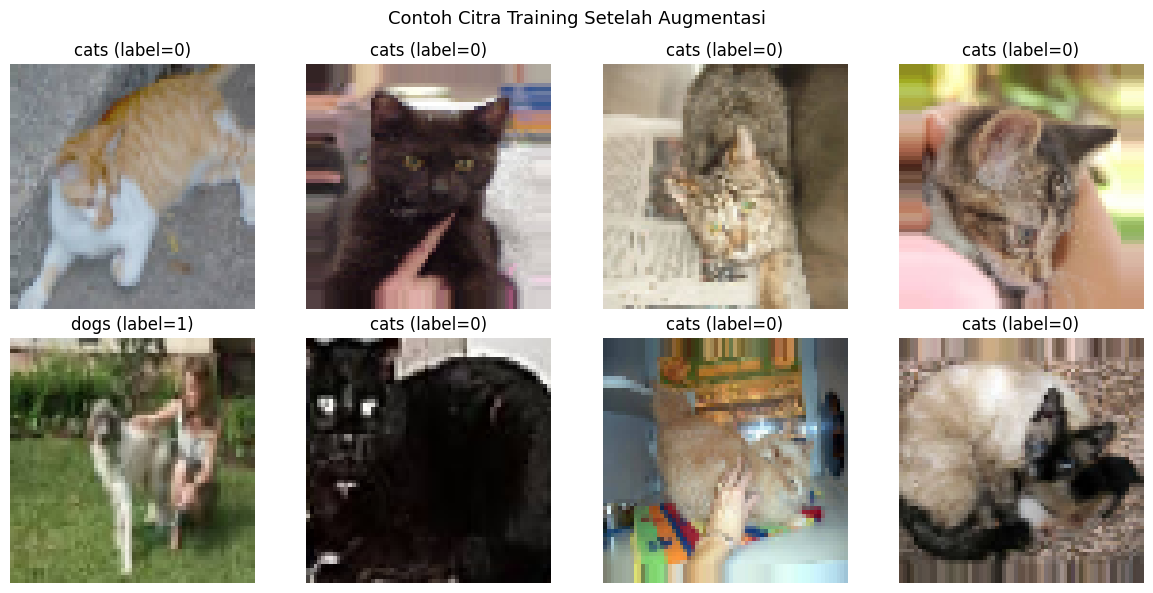

In [5]:
images, labels = next(training_set)
training_set.reset()

class_names = {v: k for k, v in training_set.class_indices.items()}

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i])
    ax.set_title(f'{class_names[int(labels[i])]} (label={int(labels[i])})')
    ax.axis('off')

plt.suptitle('Contoh Citra Training Setelah Augmentasi', fontsize=13)
plt.tight_layout()
plt.show()

## Langkah 3 - Pembuatan Model CNN

### Langkah 3.1 - Inisiasi Model CNN

In [6]:
cnn = tf.keras.models.Sequential()

### Langkah 3.2 - Layer Konvolusi 1

In [7]:
cnn.add(tf.keras.layers.Conv2D(
    filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]
))

### Langkah 3.3 - Layer Pooling 1

In [8]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.4 - Layer Konvolusi 2 dan Pooling 2

In [9]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.5 - Flattening

In [10]:
cnn.add(tf.keras.layers.Flatten())

### Langkah 3.6 - Fully Connected Layer 1 (Input)

In [11]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Langkah 3.7 - Fully Connected Layer 2 (Output)

In [12]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [13]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 3.8 - Compile Model CNN

Loss `binary_crossentropy` digunakan karena klasifikasi hanya memiliki dua kelas
(kucing dan anjing).

In [14]:
cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Langkah 4 - Fit CNN

In [15]:
history = cnn.fit(
    x=training_set,
    validation_data=test_set,
    epochs=25,
    verbose=2
)

Epoch 1/25


250/250 - 11s - 42ms/step - accuracy: 0.6286 - loss: 0.6400 - val_accuracy: 0.6940 - val_loss: 0.5755


Epoch 2/25


250/250 - 12s - 49ms/step - accuracy: 0.6951 - loss: 0.5714 - val_accuracy: 0.7195 - val_loss: 0.5459


Epoch 3/25


250/250 - 13s - 52ms/step - accuracy: 0.7231 - loss: 0.5346 - val_accuracy: 0.7315 - val_loss: 0.5516


... (40 outputs left out)

Epoch 24/25


250/250 - 12s - 48ms/step - accuracy: 0.9162 - loss: 0.1998 - val_accuracy: 0.8135 - val_loss: 0.5334


Epoch 25/25


250/250 - 12s - 48ms/step - accuracy: 0.9235 - loss: 0.1975 - val_accuracy: 0.8230 - val_loss: 0.4875


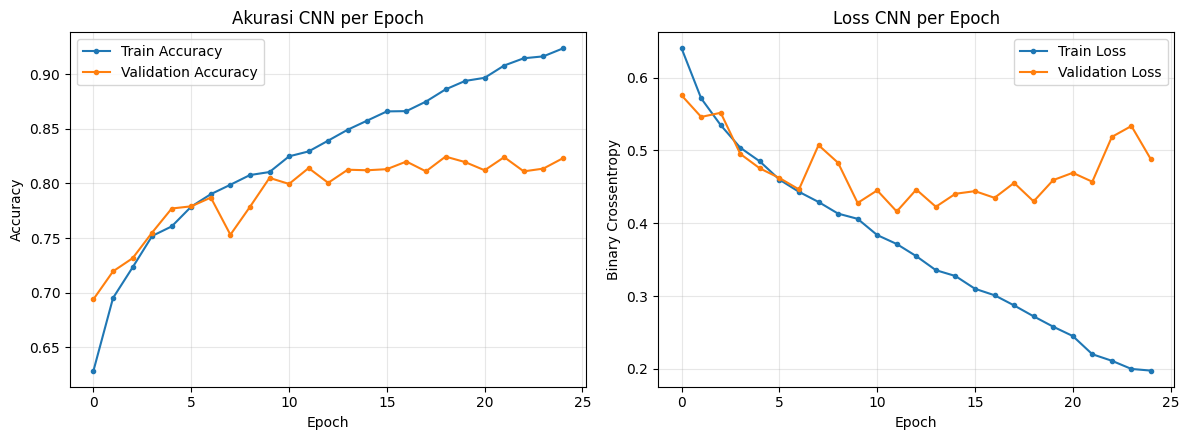

In [16]:
# Kurva akurasi dan loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history.history['accuracy'], marker='o', markersize=3, label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], marker='o', markersize=3, label='Validation Accuracy')
axes[0].set_title('Akurasi CNN per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], marker='o', markersize=3, label='Train Loss')
axes[1].plot(history.history['val_loss'], marker='o', markersize=3, label='Validation Loss')
axes[1].set_title('Loss CNN per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Binary Crossentropy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Langkah 4.1 - Evaluasi pada Data Uji

In [17]:
test_loss, test_acc = cnn.evaluate(test_set_eval, verbose=0)

print(f'Test Loss     : {test_loss:.4f}')
print(f'Test Accuracy : {test_acc:.4f} ({test_acc * 100:.2f}%)')

final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
print(f'Train Accuracy (epoch terakhir) : {final_train_acc:.4f}')
print(f'Val Accuracy   (epoch terakhir) : {final_val_acc:.4f}')

Test Loss     : 0.4875
Test Accuracy : 0.8230 (82.30%)
Train Accuracy (epoch terakhir) : 0.9235
Val Accuracy   (epoch terakhir) : 0.8230


Confusion Matrix:
[[782 218]
 [136 864]]

Classification Report:
              precision    recall  f1-score   support

        cats       0.85      0.78      0.82      1000
        dogs       0.80      0.86      0.83      1000

    accuracy                           0.82      2000
   macro avg       0.83      0.82      0.82      2000
weighted avg       0.83      0.82      0.82      2000



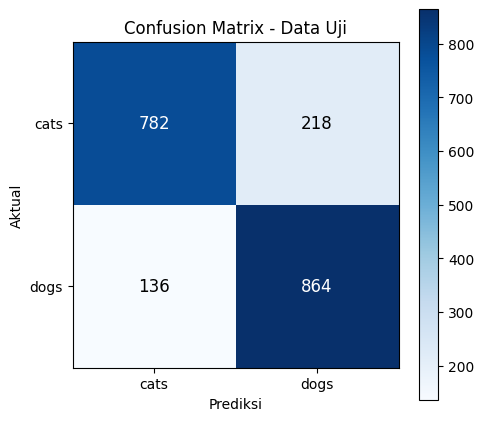

In [18]:
# Confusion matrix dan classification report
y_prob = cnn.predict(test_set_eval, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = np.array(test_set_eval.classes)

cm = confusion_matrix(y_true, y_pred)
print('Confusion Matrix:')
print(cm)

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=['cats', 'dogs']))

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['cats', 'dogs']); ax.set_yticklabels(['cats', 'dogs'])
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix - Data Uji')

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)

plt.colorbar(im)
plt.tight_layout()
plt.show()

## Langkah 5 - Prediksi dengan Satu Citra

In [19]:
def predict_single_image(path):
    test_image = keras_image.load_img(path, target_size=(64, 64))
    test_array = keras_image.img_to_array(test_image)
    test_array = np.expand_dims(test_array, axis=0)

    result = cnn.predict(test_array, verbose=0)

    if result[0][0] == 1:
        prediction = 'dog'
    else:
        prediction = 'cat'

    return test_image, float(result[0][0]), prediction

Class indices: {'cats': 0, 'dogs': 1}
cat_or_dog_1.jpg: prob(dog) = 1.0000, prediksi = dog


cat_or_dog_2.jpg: prob(dog) = 0.0000, prediksi = cat


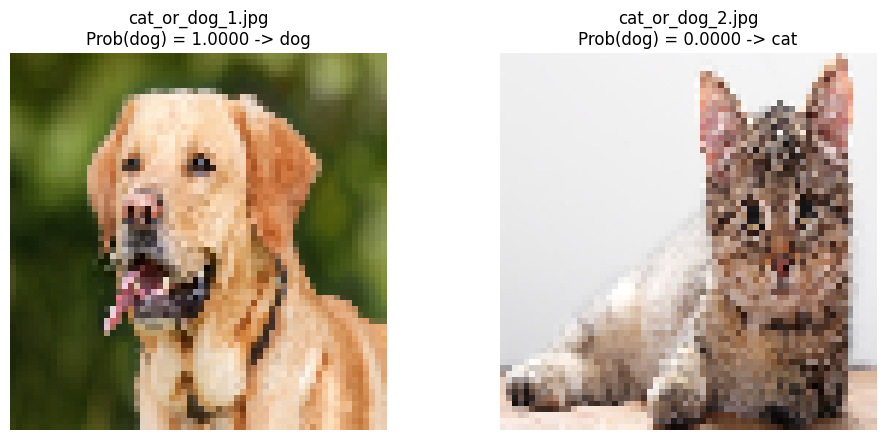

In [20]:
class_indices = training_set.class_indices
print('Class indices:', class_indices)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, filename in zip(axes, ['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']):
    path = f'dataset/single_prediction/{filename}'
    img, prob, pred = predict_single_image(path)

    ax.imshow(img)
    ax.set_title(f'{filename}\nProb(dog) = {prob:.4f} -> {pred}')
    ax.axis('off')

    print(f'{filename}: prob(dog) = {prob:.4f}, prediksi = {pred}')

plt.tight_layout()
plt.show()

## Analisis

- Model CNN sederhana dengan **2 layer konvolusi (32 filter)** dan **2 layer max pooling**
  berhasil mempelajari pola visual pembeda kucing dan anjing dengan cukup baik.
- **Augmentasi data** (shear, zoom, horizontal flip) membantu model lebih tahan terhadap
  variasi posisi, skala, dan orientasi citra sehingga mengurangi overfitting.
- Selisih akurasi training dan validation menunjukkan seberapa besar model mengalami
  overfitting. Jika akurasi training jauh lebih tinggi daripada validation, diperlukan
  augmentasi tambahan, dropout, atau early stopping.
- Prediksi satu citra dilakukan dengan mengubah citra menjadi array 64x64x3, menambahkan
  dimensi batch, lalu mengambil nilai probabilitas output sigmoid:
  nilai 1 (>= 0.5) berarti **dog**, nilai 0 (< 0.5) berarti **cat**.
- Arsitektur ini masih sederhana; penggunaan CNN yang lebih dalam, transfer learning
  (mis. VGG16/MobileNet), atau resolusi citra yang lebih besar dapat meningkatkan akurasi.

## Kesimpulan

In [21]:
print('=== Ringkasan Hasil CNN Kucing vs Anjing ===')
print(f'Jumlah data latih : {training_set.samples}')
print(f'Jumlah data uji   : {test_set_eval.samples}')
print(f'Epoch             : {len(history.history["loss"])}')
print(f'Final Train Acc   : {history.history["accuracy"][-1]:.4f}')
print(f'Final Val Acc     : {history.history["val_accuracy"][-1]:.4f}')
print(f'Test Accuracy     : {test_acc:.4f}')
print(f'Test Loss         : {test_loss:.4f}')

=== Ringkasan Hasil CNN Kucing vs Anjing ===
Jumlah data latih : 8000
Jumlah data uji   : 2000
Epoch             : 25
Final Train Acc   : 0.9235
Final Val Acc     : 0.8230
Test Accuracy     : 0.8230
Test Loss         : 0.4875
